# Lossless two-fin inverse design — simultaneous transmission exceptional points

**Task:** find one reciprocal, lossless two-fin unit cell whose *forward* and *backward* $2\times2$ transmission Jones blocks have second-order exceptional points (EPs). Work at $\lambda=633$ nm with **strictly real** $n_\mathrm{fin}=1.76$ and $n_\mathrm{sub}=1.46$.

This is a **new notebook**. The prior `TwoFin_EP_Inverse_Design.ipynb` remains the absorbing-material, full-$4\times4$ scattering EP experiment. We reuse its `engine_rcwa.py`, `engine_geometry.py`, and `engine_inverse.py`, adding `engine_transmission_ep.py` without changing their prior behavior.

### Critical distinctions

- The *complete* $S\in\mathbb C^{4\times4}$ must be **unitary** for the lossless zeroth-order four-channel model; it cannot have an EP.
- The *transmission blocks* $T_{21}$ and $T_{12}$ are generally nonunitary because of reflection, and can be nonnormal/defective without absorption.
- With reciprocal, power-normalized channels and **the same laboratory linear basis** on both sides, $T_{12}=T_{21}^{T}$. Transposition preserves eigenvalues and Jordan structure. Hence one transmission EP implies the other in an exact reciprocal simulation; we test both separately for numerical error.
- Circular basis is a **unitary similarity transform**, $T_\circ=U^\dagger T_{xy}U$, with $U=(|R\rangle,|L\rangle)$, $|R\rangle=(1,i)^T/\sqrt2$. It does not create or remove an EP. We use a fixed **laboratory-defined** circular basis for both propagation directions; a helicity-relative convention needs an additional label exchange on reversal.
- The EP search is numerical. A tiny discriminant and a high eigenvector overlap are not enough: near-scalar degeneracies, discretization and nonsmooth binary geometry need to be excluded.

## 1 · Configure GPU workload and fixed phase reference

Run this notebook from the repository directory containing the engine modules and copy `engine_transmission_ep.py` alongside them. The heavy cells are checkpointed and can be individually disabled. No FDTD solves are required.

In [ ]:
# Shared engines live in ../core (see ../PROJECTS.md). Run with the notebook folder as cwd.
import sys; from pathlib import Path
sys.path.insert(0, str((Path.cwd().parent / 'core').resolve()))

In [ ]:
from pathlib import Path
from dataclasses import asdict
import hashlib, json, time
import engine_transmission_ep, engine_rcwa, engine_geometry
import numpy as np
import matplotlib.pyplot as plt
import torch
import engine_inverse

from twofin import Config, draw_geometry, write_gds, stokes
from engine_rcwa import Settings as RCWASettings, solve as rcwa_solve, solve_torch
from engine_inverse import BOUNDS, FIXED_PORTS
from engine_transmission_ep import (
    VERSION, KEYS, circular_unitary, circular_blocks, discrim_numpy,
    loss_torch, LosslessDesign, to_tensors, simulate_lossless,
    diagnostics, report, screen_candidate, generate_seeds,
    adam_refine, physical_config, save_result, load_result,
    track_pair, loop_exchange,
)

OUT = Path('results/lossless_transmission_ep')
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Runtime toggles; cache avoids repeating expensive optimization.
RUN_GRADIENT_TEST = True
RUN_OPTIMIZATION = True
FORCE_OPTIMIZATION = True
RUN_HARD_VERIFICATION = True
RUN_HARD_POLISH = True     # Optional extra binary RCWA solves
RUN_ENCIRCLING = True    # ~41 additional high-order solves
RUN_EP_MAP = True        # ~49 additional high-order solves

N_SCREEN, KEEP = 1024, 8
COARSE_ITER, REFINE_ITER = 220, 160
SMOOTH_EDGE_UM = 0.006
SEED = 23

cfg = Config(wavelength=0.633, period=0.400,
             n_sub=1.46, n_fin=2.584, n_fin_kappa=0.0, height=0.350)
cfg.validate()
assert np.isrealobj(cfg.n_fin) and cfg.n_fin_kappa == 0.0

smoke_settings = RCWASettings(order=2, raster=96, device=DEVICE)
screen_settings = RCWASettings(order=4, raster=160, device=DEVICE)
coarse_settings = RCWASettings(order=5, raster=192, device=DEVICE)
refine_settings = RCWASettings(order=6, raster=224, device=DEVICE, precision="complex128")

print('Device:', DEVICE, '| CUDA:', torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'unavailable')
print('Strict lossless model: n_fin =', cfg.n_fin, '+ 0i')
print('Monitor reference planes (µm):', FIXED_PORTS)
print('Number of free parameters:',len(KEYS), KEYS)
print('TORCWA order stages: 2 smoke, 3 screen, 4 Adam, 5 refine, 5/7/9 validation')

Device: cuda | CUDA: NVIDIA RTX A6000
Strict lossless model: n_fin = 2.584 + 0i
Monitor reference planes (µm): (-0.52, 1.05)
Number of free parameters: 11 ('L1', 'W1', 'theta1', 'x1', 'y1', 'L2', 'W2', 'theta2', 'x2', 'y2', 'height')
TORCWA order stages: 2 smoke, 3 screen, 4 Adam, 5 refine, 5/7/9 validation


## 2 · EP objective and its physical meaning

For a complex Jones matrix $J=\begin{pmatrix}a&b\\c&d\end{pmatrix}$ define

$$\Delta(J)=(a-d)^2+4bc,\qquad\mu=\frac12\operatorname{tr}J,\qquad Q=J-\mu I.$$

At a second-order EP, $\Delta=0$ but $Q\ne0$ (rank-one nilpotent). In contrast $J=\mu I$ has equal eigenvalues but **two independent eigenvectors**. The differentiable search loss penalizes normalized $|\Delta|^2$ and weak $\|Q\|_F$, plus unphysical losslessness and reciprocity residuals. The resulting loss is only a *search heuristic*.

The 11 free parameters are independent $L_i,W_i,\theta_i,x_i,y_i$ for $i=1,2$ and common height $h$. The extinction coefficient is **not an optimizer variable** and remains exactly $\kappa=0$. Corners of both rotated rectangles are constrained to remain inside the periodic cell. Smooth edges allow autograd; **binary polygon hardening and RCWA-order convergence are essential**.

In [2]:
# Algebra-only checks before invoking the electromagnetic solver.
U = circular_unitary()
assert np.allclose(U.conj().T @ U, np.eye(2))
J_ep = 0.25 * np.array([[1j, 1], [1, -1j]], complex)
J_scalar = 0.25 * np.eye(2, dtype=complex)
assert abs(discrim_numpy(J_ep)) < 1e-12
assert abs(discrim_numpy(J_scalar)) < 1e-12
from engine_transmission_ep import block_diagnostics
assert block_diagnostics(J_ep)['jordan_strength'] > .5
assert block_diagnostics(J_scalar)['jordan_strength'] < 1e-10

print('Twofold degeneracy is insufficient: EP has Q != 0, scalar degeneracy has Q = 0.')
print('Reciprocity gives T12 = T21.T in lab xy basis; circular results are similar/transposed with helicity relabeling.')

Twofold degeneracy is insufficient: EP has Q != 0, scalar degeneracy has Q = 0.
Reciprocity gives T12 = T21.T in lab xy basis; circular results are similar/transposed with helicity relabeling.


## 3 · GPU autograd smoke test

Before running an optimization, compare the analytic PyTorch gradient of a smooth-geometry objective with a central finite difference *of the same smooth geometry*. A finite difference of sharp-edged GDS polygons is **not** a valid reference for these gradients.

In [3]:
seed_guess = {k:(lo+hi)/2 for k,(lo,hi) in BOUNDS.items() if k!='kappa'}
seed_guess.update(theta1=0.18,theta2=1.03,x1=-0.025,y1=-0.050,
                  x2=0.051,y2=0.042)
seed_guess['kappa'] = 0.0

if RUN_GRADIENT_TEST:
    p=to_tensors(seed_guess,device=DEVICE)
    p['theta1']=p['theta1'].clone().detach().requires_grad_(True)
    loss, S_smoke, parts=simulate_lossless(cfg,smoke_settings,p,edge_um=.010)
    grad=torch.autograd.grad(loss,p['theta1'])[0]
    def loss_at_angle(angle):
        q=to_tensors({**seed_guess,'theta1':float(angle)},device=DEVICE)
        with torch.no_grad():
            l,_,_=simulate_lossless(cfg,smoke_settings,q,edge_um=.010)
        return float(l.cpu())
    h=2e-3
    finite_diff=(loss_at_angle(seed_guess['theta1']+h)-loss_at_angle(seed_guess['theta1']-h))/(2*h)
    autodiff=float(grad.detach().cpu())
    relative_error=abs(autodiff-finite_diff)/max(abs(autodiff),abs(finite_diff),1e-5)
    print(f'Objective = {float(loss.detach().cpu()):.5g}, autograd = {autodiff:.5g}, '
          f'finite difference = {finite_diff:.5g}, relative error = {relative_error:.3f}')
    if not np.isfinite([autodiff,finite_diff]).all() or relative_error > 0.30:
        raise RuntimeError('Autograd did not agree with finite differences; do not launch optimizer.')
    print('Gradient smoke test PASSED (TORCWA differentiable geometry).')

Objective = 0.17458, autograd = 0.73902, finite difference = 0.7413, relative error = 0.003
Gradient smoke test PASSED (TORCWA differentiable geometry).


## 4 · Multistart optimization, strictly lossless

Each electromagnetic evaluation returns the complete $4\times4$ complex $S$, but the loss targets **both circular transmission blocks**. Use Sobol exploration followed by bounded Adam, then refinement with more RCWA harmonics. We optimize both directions, even though reciprocity makes the exact EP constraints redundant. The checkpoint is keyed to the physical model and numerical settings.

In [4]:
code_signature = {
    m.__name__: hashlib.sha256(
        Path(m.__file__).read_bytes()
    ).hexdigest()[:12]
    for m in (
        engine_transmission_ep,
        engine_rcwa,
        engine_geometry,
        engine_inverse
    )
}

run_parameters=dict(version=VERSION,code_signature=code_signature,
    config=asdict(cfg),fixed_ports=FIXED_PORTS,
    screen=asdict(screen_settings),coarse=asdict(coarse_settings),refine=asdict(refine_settings),
    count=N_SCREEN,keep=KEEP,steps=(COARSE_ITER,REFINE_ITER),
    edge=SMOOTH_EDGE_UM,seed=SEED)

run_parameters.update(
    bounds={k: list(v) for k, v in BOUNDS.items()},
    coarse_lr=0.030,
    refine_lr=0.008,
    coarse_patience=90,
    refine_patience=100,
    refine_top_k=3,
)

run_id=hashlib.sha256(json.dumps(run_parameters,sort_keys=True).encode()).hexdigest()[:14]
checkpoint=OUT/f'candidate_{run_id}.npz'
best=None

if checkpoint.exists() and not FORCE_OPTIMIZATION:
    best=load_result(checkpoint)
    print('Reused checkpoint:', checkpoint)
elif RUN_OPTIMIZATION:
    starts,rankings=generate_seeds(cfg,screen_settings,count=N_SCREEN,keep=KEEP,
                                    seed=SEED,edge_um=.010)
    print('Best Sobol-screen objectives:',[round(float(x[0]),5) for x in rankings[:KEEP]])
    attempts=[]
    for index,initial in enumerate(starts,1):
        print(f'Coarse Adam start {index}/{len(starts)}')
        try:
            result=adam_refine(cfg,coarse_settings,initial,iterations=COARSE_ITER,
                               lr=.030,edge_um=SMOOTH_EDGE_UM, patience=90)
            attempts.append(result)
        except (RuntimeError,ValueError) as exc:
            print('Skipped failed Adam start:',exc)
    if not attempts:
        raise RuntimeError('No valid optimizer trajectories; inspect TORCWA diagnostics.')
    
    attempts.sort(key=lambda a: a['loss'])

    # Refine the three best coarse candidates.
    refinements = []
    n_refine = min(3, len(attempts))

    print(f'Refining {n_refine} candidates at Fourier order {refine_settings.order}')

    for index, candidate in enumerate(attempts[:n_refine], 1):
        print(f'Refining candidate {index}/{n_refine}')

        try:
            result = adam_refine(
                cfg,
                refine_settings,
                candidate['params'],
                iterations=REFINE_ITER,
                lr=0.008,
                edge_um=SMOOTH_EDGE_UM,
                patience=100
            )

            # Combine coarse and refinement histories once.
            offset = len(candidate['history'])
            result['history'] = candidate['history'] + [
                {**row, 'iteration': row['iteration'] + offset}
                for row in result['history']
            ]

            refinements.append(result)

        except (RuntimeError, ValueError) as exc:
            print(f'Refinement {index} failed: {exc}')

    if not refinements:
        raise RuntimeError('All refinement attempts failed.')

    # Select the best candidate at the higher RCWA order.
    best = min(refinements, key=lambda r: r['loss'])

    best['metadata'] = run_parameters
    save_result(checkpoint, best, metadata=run_parameters)

    print('Best refined loss:', best['loss'])
    print('Saved checkpoint:', checkpoint)

else:
    print('Search disabled; RUN_OPTIMIZATION=True or reuse existing checkpoint.')

Screened 8/128; viable 8
Screened 16/128; viable 16
Screened 24/128; viable 24
Screened 32/128; viable 32
Screened 40/128; viable 40
Screened 48/128; viable 48
Screened 56/128; viable 56
Screened 64/128; viable 64
Screened 72/128; viable 72
Screened 80/128; viable 80
Screened 88/128; viable 88
Screened 96/128; viable 96
Screened 104/128; viable 104
Screened 112/128; viable 112
Screened 120/128; viable 120
Screened 128/128; viable 128
Best Sobol-screen objectives: [0.00291, 0.00297, 0.00374, 0.00449, 0.00454, 0.00668, 0.00751, 0.00856]
Coarse Adam start 1/8
   10/220: loss=0.003487, disc=9.683e-03, strength=0.070
   20/220: loss=0.002892, disc=1.136e-02, strength=0.075
   30/220: loss=0.002912, disc=1.169e-02, strength=0.077
   40/220: loss=0.002924, disc=1.177e-02, strength=0.077
   50/220: loss=0.002904, disc=1.161e-02, strength=0.076
   60/220: loss=0.002892, disc=1.134e-02, strength=0.075
   70/220: loss=0.002894, disc=1.126e-02, strength=0.075
   80/220: loss=0.002892, disc=1.140e-

## 5 · Soft-geometry candidate and EP diagnostics

An optimizer minimum is **not** a fabricated EP. Here we examine the actual complex matrices, their spectra and eigenvectors, and the unitarity of the full $S$. The determinant or eigenvalue phases include the propagation phase at the chosen reference planes.

Soft geometry objective: 1.5869759697327175e-08
L1        +0.21431 µm
W1        +0.09966 µm
theta1     +65.981 deg
x1        +0.01595 µm
y1        -0.07546 µm
L2        +0.26007 µm
W2        +0.13305 µm
theta2     +75.622 deg
x2        -0.00023 µm
y2        -0.05125 µm
height    +0.29661 µm
kappa = 0.0 (fixed, not optimized)

Smooth-geometry candidate  [circular basis R=(x+iy)/sqrt(2)]
S†S-I (spectral norm): 2.851e-08; S-Sᵀ (Frobenius): 3.224e-13
T21: gap=5.307e-03, overlap=0.999399, disc_norm=2.817e-05, Jordan=0.153, rank ratio=3.004e-04, Tavg=0.7308
  λ = [0.6573845+0.5257109j 0.6633544+0.5280633j]
T12: gap=5.307e-03, overlap=0.999399, disc_norm=2.817e-05, Jordan=0.153, rank ratio=3.004e-04, Tavg=0.7308
  λ = [0.6633544+0.5280633j 0.6573845+0.5257109j]
NEAR-EP SCREEN: NOT VALIDATED
  T21: eigenvalue gap too large; T12: eigenvalue gap too large


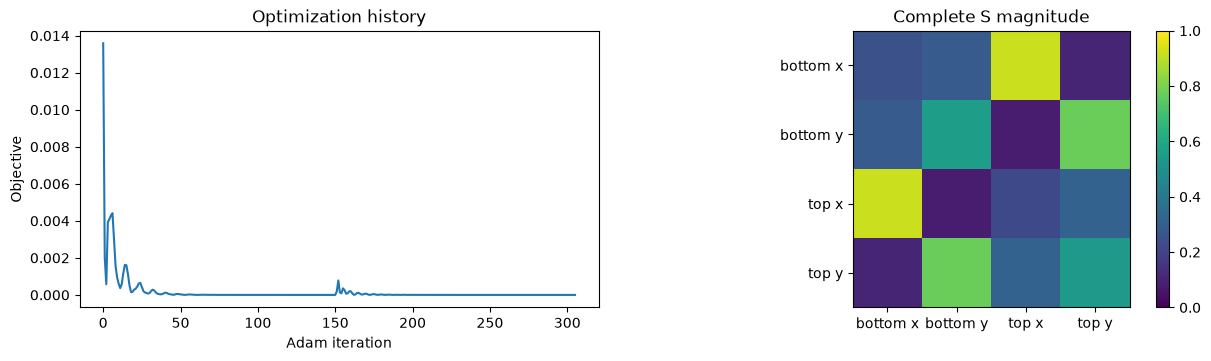

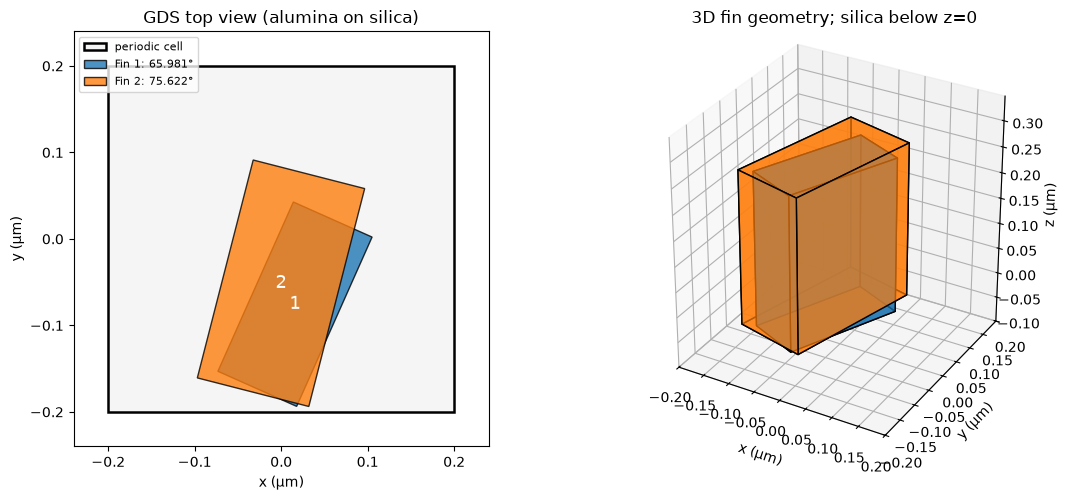

In [5]:
if best is not None:
    print('Soft geometry objective:',best['loss'])
    for k in KEYS:
        v=best['params'][k]
        print(f'{k:8} {np.rad2deg(v):+9.3f} deg' if k.startswith('theta') else f'{k:8} {v:+9.5f} µm')
    print('kappa =',best['params']['kappa'],'(fixed, not optimized)')
    ds,soft_pass=report(best['S'],'Smooth-geometry candidate')
    fig,ax=plt.subplots(1,2,figsize=(12,3.5),layout='constrained')
    history=best['history']
    ax[0].plot([r['iteration'] for r in history],[r['loss'] for r in history])
    ax[0].set(xlabel='Adam iteration',ylabel='Objective',title='Optimization history')
    labels=['bottom x','bottom y','top x','top y']
    im=ax[1].imshow(np.abs(best['S']),cmap='viridis',vmin=0,vmax=1)
    ax[1].set(xticks=range(4),yticks=range(4),xticklabels=labels,yticklabels=labels,
              title='Complete S magnitude')
    fig.colorbar(im,ax=ax[1]);plt.show()

    initial_cfg=physical_config(cfg,best['params'])
    fig=draw_geometry(initial_cfg); plt.show()

## 6 · Compare both circular Jones matrices and eigenpolarizations

$U^\dagger T U$ converts each lab-coordinate Jones block to $R/L$. Because the basis transformation is unitary, eigenvalue degeneracy and eigenvector orthogonality are basis invariant. The eigenvectors plotted on the Poincaré sphere are first transformed *back to $x/y$* for the existing Stokes convention.

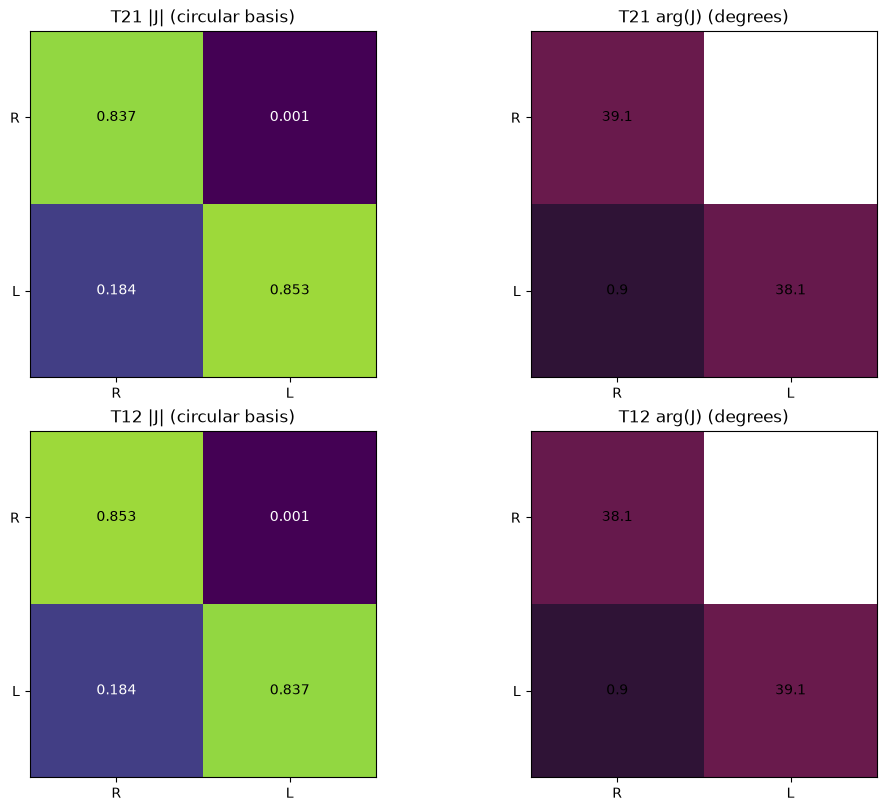

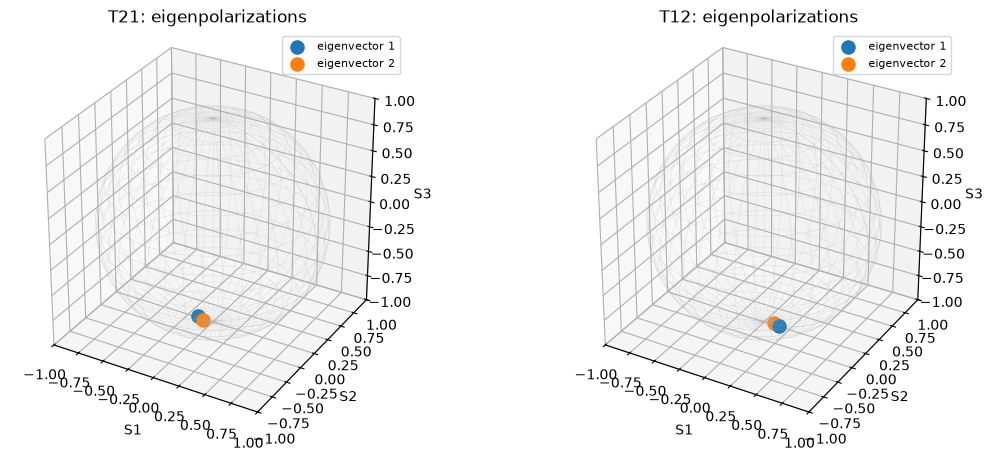

In [6]:
if best is not None:
    df=diagnostics(best['S'])
    U=circular_unitary()
    fig,axes=plt.subplots(2,2,figsize=(10,8),layout='constrained')
    for row,name in enumerate(('T21','T12')):
        J=df[name+'_circular']; d=df[name]
        im=axes[row,0].imshow(np.abs(J),vmin=0,vmax=1,cmap='viridis')
        axes[row,0].set(xticks=(0,1),yticks=(0,1),xticklabels=('R','L'),
                        yticklabels=('R','L'),title=f'{name} |J| (circular basis)')
        for (i,j),z in np.ndenumerate(J):
            axes[row,0].text(j,i,f'{abs(z):.3f}',ha='center',va='center',color='white' if abs(z)<.4 else 'black')
        ph=np.rad2deg(np.angle(J)); ph[np.abs(J)<.001]=np.nan
        im=axes[row,1].imshow(ph,vmin=-180,vmax=180,cmap='twilight')
        axes[row,1].set(xticks=(0,1),yticks=(0,1),xticklabels=('R','L'),
                        yticklabels=('R','L'),title=f'{name} arg(J) (degrees)')
        for i in range(2):
            for j in range(2):
                if np.isfinite(ph[i,j]):axes[row,1].text(j,i,f'{ph[i,j]:.1f}',ha='center',va='center')
    plt.show()

    fig=plt.figure(figsize=(11,4.5),layout='constrained')
    for i,name in enumerate(('T21','T12')):
        ax=fig.add_subplot(1,2,i+1,projection='3d')
        u,v=np.mgrid[0:2*np.pi:40j,0:np.pi:20j]
        ax.plot_wireframe(np.cos(u)*np.sin(v),np.sin(u)*np.sin(v),np.cos(v),
                          color='.7',alpha=.25,lw=.5)
        eig=df[name]['eigenvectors']
        for j in (0,1):
            s=stokes(U@eig[:,j])[1:]
            ax.scatter(*s,s=90,label=f'eigenvector {j+1}')
        ax.set(xlim=(-1,1),ylim=(-1,1),zlim=(-1,1),xlabel='S1',ylabel='S2',zlabel='S3',
               title=f'{name}: eigenpolarizations')
        ax.set_box_aspect((1,1,1));ax.legend(fontsize=8)
    plt.show()

## 7 · **Required** hard-edge verification and RCWA convergence

The differentiable geometry has smeared boundaries; a low soft-geometry loss does **not** establish an EP in a physically fabricated polygon. We reconstruct the exact two fins via `Config`, calculate binary RCWA at increasing Fourier order, and compare the complete complex $S$ matrices. Material loss is fixed to zero throughout.

If the hardened candidate is not near an EP, **report failure** rather than calling it successful. Additional binary optimization may be necessary. The hardest check is at the highest specified Fourier order, not the training order.

In [7]:
hard_S = {}
hard_cfg = None
if best is not None and RUN_HARD_VERIFICATION:
    hard_cfg=physical_config(cfg,best['params'])
    assert hard_cfg.n_fin_kappa == 0
    write_gds(hard_cfg,OUT/'lossless_candidate.gds')
    hard_cache=OUT/f'hard_edge_{run_id}.npz'
    if hard_cache.exists() and not FORCE_OPTIMIZATION:
        with np.load(hard_cache,allow_pickle=False) as f:
            hard_S={int(k.split('_')[-1]):f[k] for k in f.files}
        print('Reused cached binary RCWA matrices:',hard_cache)
    else:
        for order,raster in ((5,160),(7,192),(9,224)):
            settings=RCWASettings(order=order,raster=raster,device=DEVICE,
                                   precision='complex128' if DEVICE=='cuda' else 'complex64')
            t0=time.perf_counter()
            hard_S[order]=rcwa_solve(hard_cfg,settings,ports=FIXED_PORTS)['S']
            print(f'Hard-edge order={order} | {time.perf_counter()-t0:.2f} s')
        np.savez_compressed(hard_cache,**{f'S_{k}':v for k,v in hard_S.items()})
    for order,S in sorted(hard_S.items()):
        report(S,f'Hard-edge Fourier order {order}')
    for a,b in ((5,7),(7,9)):
        print(f'Complex S difference {a} -> {b}:',np.max(np.abs(hard_S[a]-hard_S[b])))
    with torch.no_grad():
        soft_at5=solve_torch(cfg,to_tensors(best['params'],device=DEVICE),
            refine_settings,edge_um=SMOOTH_EDGE_UM,ports=FIXED_PORTS).cpu().numpy()
    print('Smooth versus binary S at order 5:',np.max(abs(soft_at5-hard_S[5])))
    np.savez_compressed(OUT/'hard_edge_validation.npz',
        orders=np.array(list(hard_S)),matrices=np.array(list(hard_S.values())))

Hard-edge order=5 | 0.22 s
Hard-edge order=7 | 0.63 s
Hard-edge order=9 | 1.63 s

Hard-edge Fourier order 5  [circular basis R=(x+iy)/sqrt(2)]
S†S-I (spectral norm): 5.705e-14; S-Sᵀ (Frobenius): 6.602e-14
T21: gap=1.310e-01, overlap=0.753958, disc_norm=1.716e-02, Jordan=0.177, rank ratio=1.403e-01, Tavg=0.7076
  λ = [0.6361324+0.397492j  0.7709676+0.4755905j]
T12: gap=1.310e-01, overlap=0.753958, disc_norm=1.716e-02, Jordan=0.177, rank ratio=1.403e-01, Tavg=0.7076
  λ = [0.7709676+0.4755905j 0.6361324+0.397492j ]
NEAR-EP SCREEN: NOT VALIDATED
  T21: eigenvalue gap too large; T21: eigenvectors not coalesced; T21: not near rank-one; T12: eigenvalue gap too large; T12: eigenvectors not coalesced; T12: not near rank-one

Hard-edge Fourier order 7  [circular basis R=(x+iy)/sqrt(2)]
S†S-I (spectral norm): 2.028e-13; S-Sᵀ (Frobenius): 3.410e-13
T21: gap=1.559e-01, overlap=0.693721, disc_norm=2.429e-02, Jordan=0.186, rank ratio=1.808e-01, Tavg=0.6968
  λ = [0.633694+0.3586526j 0.791781+0.45277

## 8 · Optional binary refinement

If hard-edge verification fails, it is useful to refine the *physical* sharp-edged geometry. This optional small Powell search varies $\theta_1$ and $h$, requiring many new RCWA calls. It preserves $\kappa=0$. More general multistart binary refinement might be needed if no local solution exists. This section **does not overwrite** the smooth candidate or the previous full-S notebook.

In [8]:
polished=None
if RUN_HARD_POLISH and best is not None:
    from scipy.optimize import minimize
    from engine_inverse import enforce_unit_cell
    physical=best['params'].copy()
    keys=('theta1','height')
    x0=np.array([physical[k] for k in keys])
    bounds=[BOUNDS[k] for k in keys]
    settings=RCWASettings(order=6,raster=192,device=DEVICE)
    evals={'n':0,'best':np.inf,'p':None,'S':None}
    def objective(x):
        trial=physical.copy();trial.update(dict(zip(keys,map(float,x))))
        trial=enforce_unit_cell(trial);trial['kappa']=0.
        try:
            configuration=physical_config(cfg,trial)
            S=rcwa_solve(configuration,settings,ports=FIXED_PORTS)['S']
            d=diagnostics(S)
            w=d['T21']
            score=np.log1p(20*w['discriminant_norm']**2) + 15*max(0,.08-w['jordan_strength'])**2
            score+=2*d['unitarity_error']**2+2*d['reciprocity_error']**2
            evals['n']+=1
            if score<evals['best']:evals.update(best=score,p=trial.copy(),S=S.copy())
            return score
        except (ValueError,RuntimeError):
            return 100.
    result=minimize(objective,x0,method='Powell',bounds=bounds,
                    options={'maxfev':35,'xtol':1e-3,'ftol':1e-3})
    polished=evals
    print('Hard-edge polish:',result.message,'evaluations:',evals['n'])
    if polished['S'] is not None:
        report(polished['S'],'Polished hard-edge, order 6')
        if RUN_HARD_VERIFICATION:
            print('Revalidating polished physical geometry at orders 5, 7 and 9...')
            hard_cfg=physical_config(cfg,polished['p'])
            hard_S={}
            for order,raster in ((5,160),(7,192),(9,224)):
                settings=RCWASettings(order=order,raster=raster,device=DEVICE,
                     precision='complex128' if DEVICE=='cuda' else 'complex64')
                hard_S[order]=rcwa_solve(hard_cfg,settings,ports=FIXED_PORTS)['S']
                report(hard_S[order],f'Polished hard-edge order {order}')
            write_gds(hard_cfg,OUT/'lossless_polished_candidate.gds')

Hard-edge polish: Maximum number of function evaluations has been exceeded. evaluations: 35

Polished hard-edge, order 6  [circular basis R=(x+iy)/sqrt(2)]
S†S-I (spectral norm): 2.035e-04; S-Sᵀ (Frobenius): 2.754e-04
T21: gap=7.403e-02, overlap=0.916765, disc_norm=5.481e-03, Jordan=0.178, rank ratio=4.342e-02, Tavg=0.6810
  λ = [0.5386818+0.5511181j 0.5786283+0.6277297j]
T12: gap=7.376e-02, overlap=0.917390, disc_norm=5.441e-03, Jordan=0.178, rank ratio=4.308e-02, Tavg=0.6811
  λ = [0.5785673+0.6275875j 0.538759 +0.551257j ]
NEAR-EP SCREEN: NOT VALIDATED
  T21: eigenvalue gap too large; T21: eigenvectors not coalesced; T21: not near rank-one; T12: eigenvalue gap too large; T12: eigenvectors not coalesced; T12: not near rank-one
Revalidating polished physical geometry at orders 5, 7 and 9...

Polished hard-edge order 5  [circular basis R=(x+iy)/sqrt(2)]
S†S-I (spectral norm): 2.410e-13; S-Sᵀ (Frobenius): 3.079e-13
T21: gap=2.114e-02, overlap=0.992519, disc_norm=4.469e-04, Jordan=0.173,

## 9 · Optional EP encircling in two real geometric coordinates

Select $\theta_1$ and $h$ as independent control coordinates, and trace the **hard-edged** transmission eigenvalues along a closed loop about the candidate. Near an isolated second-order EP, continuously tracked eigenvalues should exchange after one circuit (and return after two). Loop radii must be varied to confirm the EP lies inside; failure to exchange means the chosen loop has not demonstrated encircling.

T21 branch exchange: False minimum eigenvalue gap on path: 0.0804554719201842
T12 branch exchange: False minimum eigenvalue gap on path: 0.08018332654132401


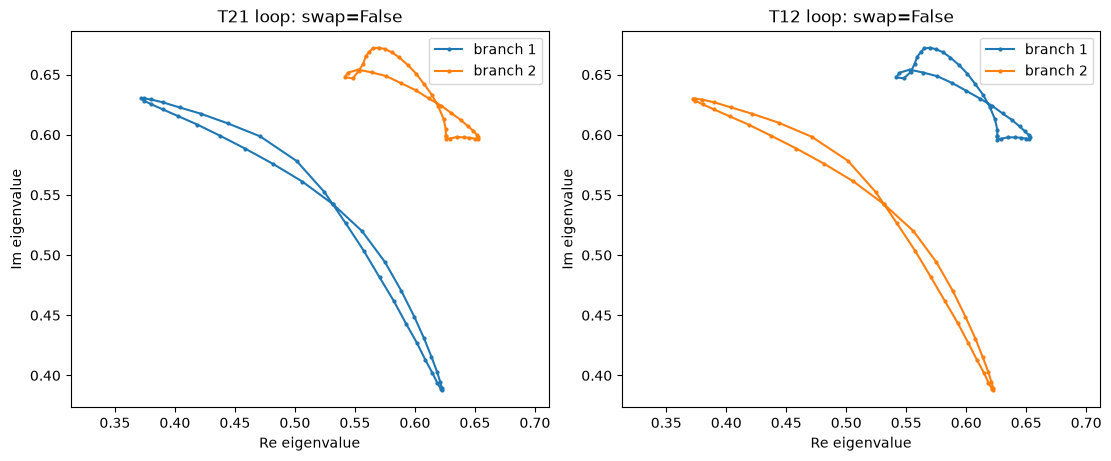

In [9]:
if RUN_ENCIRCLING and best is not None:
    base=polished['p'] if polished and polished['p'] is not None else best['params']
    loop_order=7
    settings=RCWASettings(order=loop_order,raster=192,device=DEVICE)
    t=np.linspace(0,2*np.pi,41)
    angle_radius=np.deg2rad(2.0);height_radius=.012
    series21=[];series12=[]
    for phase in t:
        trial=base.copy()
        trial['theta1']=float(np.clip(base['theta1']+angle_radius*np.cos(phase),*BOUNDS['theta1']))
        trial['height']=float(np.clip(base['height']+height_radius*np.sin(phase),*BOUNDS['height']))
        trial['kappa']=0.
        J=rcwa_solve(physical_config(cfg,trial),settings,ports=FIXED_PORTS)['S']
        J21,J12=circular_blocks(J)
        series21.append(J21);series12.append(J12)
    fig,ax=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
    for a,name,series in zip(ax,('T21','T12'),(series21,series12)):
        tracked=track_pair(series)
        for j in (0,1):
            a.plot(tracked[:,j].real,tracked[:,j].imag,'o-',ms=2,label=f'branch {j+1}')
        a.set(xlabel='Re eigenvalue',ylabel='Im eigenvalue',title=f'{name} loop: swap={loop_exchange(tracked)}')
        a.axis('equal');a.legend()
        print(name,'branch exchange:',loop_exchange(tracked),
              'minimum eigenvalue gap on path:',
              min(abs(np.diff(np.sort_complex(np.linalg.eigvals(M))))[0] for M in series))
    plt.show()

## 10 · Optional local two-parameter EP landscape

Plot the normalized complex discriminant magnitude versus $\theta_1$ and $h$ for the *binary* geometry. A minimum can suggest an EP location, but loss/convergence checks and loop topology remain necessary. This scan does **not** change material index.

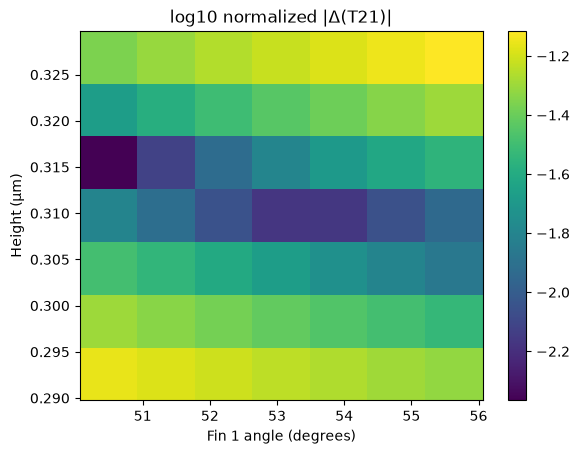

In [10]:
if RUN_EP_MAP and best is not None:
    base=polished['p'] if polished and polished['p'] is not None else best['params']
    settings=RCWASettings(order=7,raster=192,device=DEVICE)
    angles=base['theta1']+np.deg2rad(np.linspace(-3,3,7))
    heights=base['height']+np.linspace(-.02,.02,7)
    scan=np.full((len(heights),len(angles)),np.nan)
    for i,h in enumerate(heights):
        for j,theta in enumerate(angles):
            trial=base.copy();trial.update(theta1=float(theta),height=float(h),kappa=0.)
            try:
                S=rcwa_solve(physical_config(cfg,trial),settings,ports=FIXED_PORTS)['S']
                scan[i,j]=diagnostics(S)['T21']['discriminant_norm']
            except (ValueError,RuntimeError):pass
    fig,ax=plt.subplots(figsize=(6.5,4.8))
    im=ax.imshow(np.log10(np.maximum(scan,1e-12)),origin='lower',aspect='auto',
        extent=[np.rad2deg(angles[0]),np.rad2deg(angles[-1]),heights[0],heights[-1]])
    ax.set(xlabel='Fin 1 angle (degrees)',ylabel='Height (µm)',title='log10 normalized |Δ(T21)|')
    fig.colorbar(im,ax=ax);plt.show()

## 11 · Acceptance decision, phase preservation, and export

A *numerical near-EP* requires both $T_{21}$ and $T_{12}$ to have small eigenvalue gaps, nearly identical eigenvectors, a nonzero traceless Jordan part, and an approximately rank-one $J-\mu I$. The complete $S$ should remain nearly **unitary and reciprocal**. These tolerances are heuristics; they must survive increasing Fourier order and decreasing geometry smoothing. Encircling evidence is strongly recommended.

A common Jones phase $\tfrac12\arg\det T$ is only defined modulo $\pi$; **all four complex Jones coefficients** and the complete $S$ are saved without stripping any common propagation phase.

In [11]:
if best is not None:
    if hard_S:
        accepted_matrix=hard_S[max(hard_S)]
        d,near_ep=report(accepted_matrix,'FINAL: binary high-order test')
        convergence_error=np.max(abs(hard_S[7]-hard_S[9]))
        convergence_ok=convergence_error<0.01  # tighten after observing phase convergence
        print('Complex order 7→9 convergence:',convergence_error,'threshold 0.01')
        near_ep=bool(near_ep and convergence_ok)
        print('FINAL STATUS:', 'NUMERICAL NEAR-EP CANDIDATE' if near_ep
              else 'EP NOT VERIFIED — refine geometry/RCWA and inspect convergence')
        S_export=accepted_matrix
    else:
        print('No binary validation; result must NOT be called an achieved EP.')
        S_export=best['S']
    J21,J12=circular_blocks(S_export)
    for name,J in (('forward T21',J21),('backward T12',J12)):
        det=np.linalg.det(J)
        if abs(det)>1e-10:
            print(name,'half determinant phase (mod 180 deg):',
                  np.rad2deg(np.angle(det))/2)
        else:
            print(name,'half determinant phase ill-conditioned (near-zero determinant)')
    outfile=OUT/'lossless_transmission_ep_candidate.npz'
    np.savez_compressed(outfile,S=S_export,T21_circular=J21,T12_circular=J12,
        params=json.dumps(polished['p'] if polished and polished['p'] is not None and RUN_HARD_VERIFICATION else best['params']),kappa=np.array(0.),
        fixed_ports=np.array(FIXED_PORTS),wavelength=np.array(cfg.wavelength),
        binary_validated=np.array(bool(hard_S)))
    print('Saved complete complex scattering matrix:',outfile)
    print('Existing absorbing/full-S EP notebook remains unchanged.')


FINAL: binary high-order test  [circular basis R=(x+iy)/sqrt(2)]
S†S-I (spectral norm): 1.867e-12; S-Sᵀ (Frobenius): 2.217e-12
T21: gap=1.213e-01, overlap=0.810503, disc_norm=1.470e-02, Jordan=0.188, rank ratio=1.047e-01, Tavg=0.6680
  λ = [0.5386799+0.5011598j 0.606517 +0.623796j ]
T12: gap=1.213e-01, overlap=0.810503, disc_norm=1.470e-02, Jordan=0.188, rank ratio=1.047e-01, Tavg=0.6680
  λ = [0.606517 +0.623796j  0.5386799+0.5011598j]
NEAR-EP SCREEN: NOT VALIDATED
  T21: eigenvalue gap too large; T21: eigenvectors not coalesced; T21: not near rank-one; T12: eigenvalue gap too large; T12: eigenvectors not coalesced; T12: not near rank-one
Complex order 7→9 convergence: 0.03279099475364982 threshold 0.01
FINAL STATUS: EP NOT VERIFIED — refine geometry/RCWA and inspect convergence
forward T21 half determinant phase (mod 180 deg): 44.36907279641297
backward T12 half determinant phase (mod 180 deg): 44.369072796412475
Saved complete complex scattering matrix: results/lossless_transmissio